In [133]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')


In [134]:
df= pd.read_csv('heart.csv')
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [135]:
df.shape

(918, 12)

In [136]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 97.6 KB


In [137]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [138]:
df.isnull().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

In [139]:
df.duplicated().sum()

np.int64(0)

<Axes: xlabel='HeartDisease'>

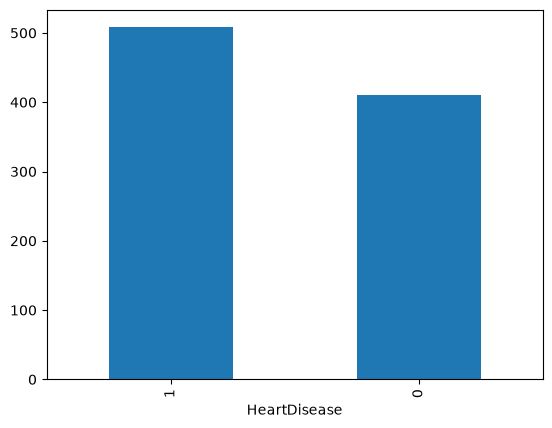

In [140]:
df['HeartDisease'].value_counts().plot(kind='bar')

In [141]:
df.columns

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='str')

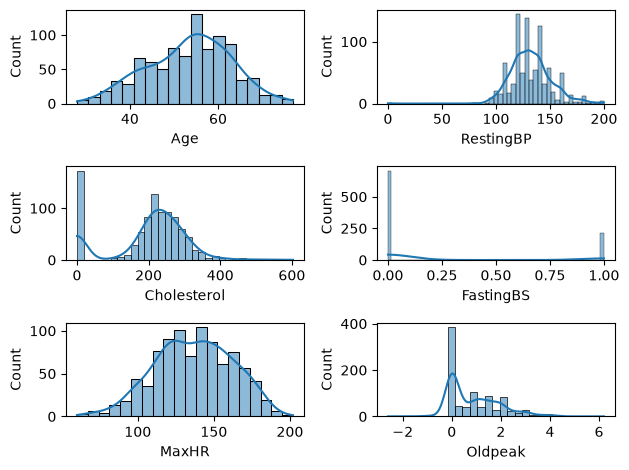

In [142]:
def plotting(var,num):
    plt.subplot(3,2,num)
    sns.histplot(df[var],kde=True)

plotting('Age',1)
plotting('RestingBP',2)
plotting('Cholesterol',3)
plotting('FastingBS',4)
plotting('MaxHR',5)
plotting('Oldpeak',6)

plt.tight_layout()
plt.show()


In [143]:
df['Cholesterol'].value_counts()

Cholesterol
0      172
254     11
223     10
220     10
211      9
      ... 
353      1
278      1
157      1
176      1
131      1
Name: count, Length: 222, dtype: int64

In [144]:
ch_mean= df.loc[df['Cholesterol']!=0,'Cholesterol'].mean()

df["Cholesterol"]= df["Cholesterol"].replace(0,ch_mean)

df["Cholesterol"]= df["Cholesterol"].round(2)


<Axes: xlabel='Cholesterol', ylabel='Count'>

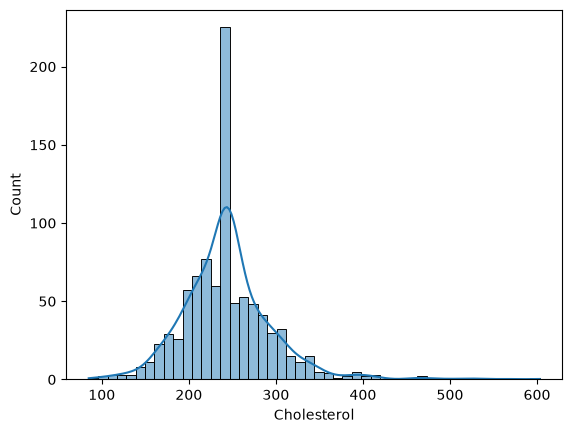

In [145]:
sns.histplot(df["Cholesterol"],kde=True)

In [146]:
(df['RestingBP']==0).sum()

np.int64(1)

In [147]:
bp_mean= df.loc[df['RestingBP']!=0,'RestingBP'].mean()
df['RestingBP']=df['RestingBP'].replace(0,bp_mean)

df["RestingBP"]=df["RestingBP"].round(3)


<Axes: xlabel='RestingBP', ylabel='Count'>

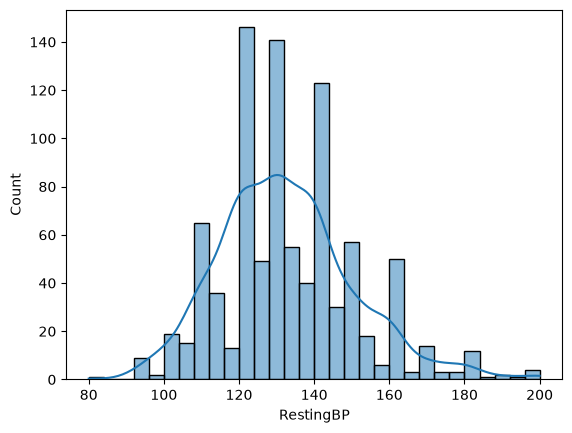

In [148]:
sns.histplot(df["RestingBP"],kde=True)

<Axes: xlabel='Sex', ylabel='count'>

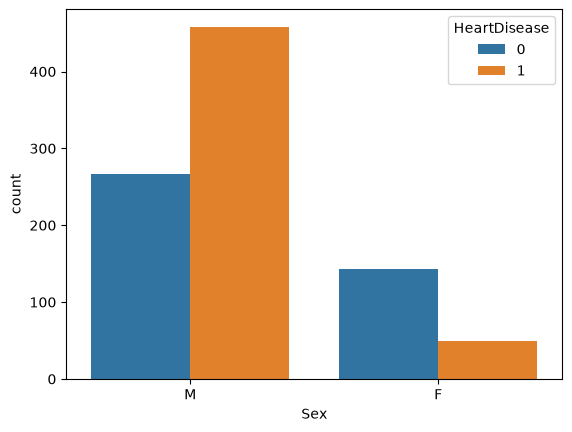

In [149]:
sns.countplot(x=df['Sex'],hue= df['HeartDisease'])

<Axes: xlabel='ExerciseAngina', ylabel='count'>

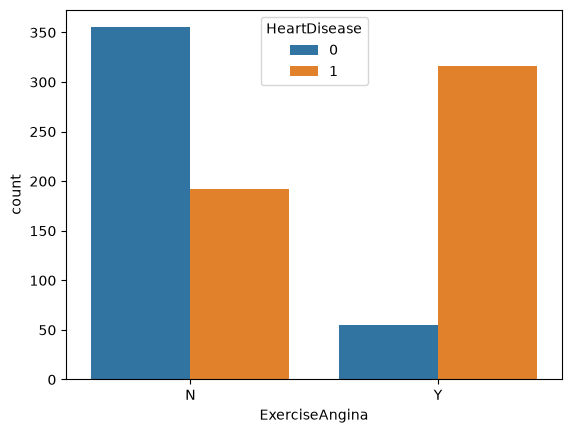

In [150]:
sns.countplot(x=df['ExerciseAngina'],hue=df['HeartDisease'])

<Axes: xlabel='RestingECG', ylabel='count'>

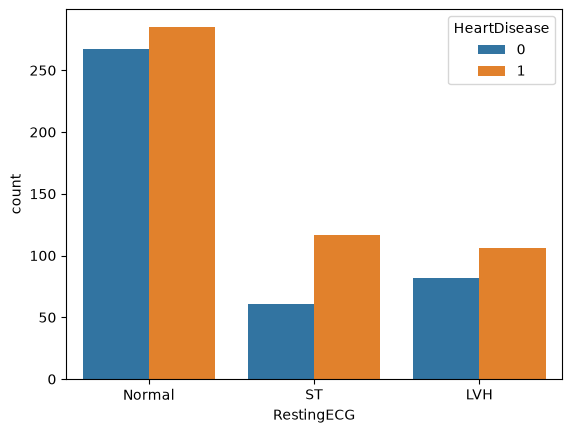

In [151]:
sns.countplot(x= df['RestingECG'],hue=df['HeartDisease'])

<Axes: xlabel='HeartDisease', ylabel='Cholesterol'>

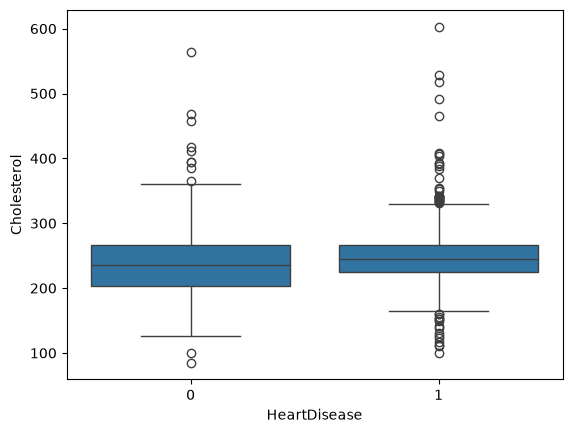

In [152]:
sns.boxplot(x=df['HeartDisease'],y=df['Cholesterol'])

<Axes: xlabel='HeartDisease', ylabel='Age'>

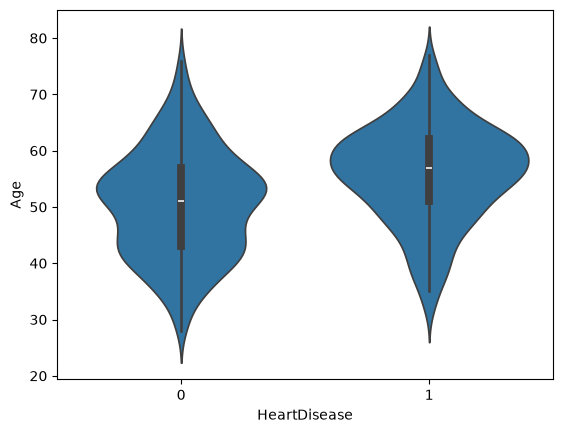

In [153]:
sns.violinplot(x='HeartDisease',y='Age',data=df)

<Axes: >

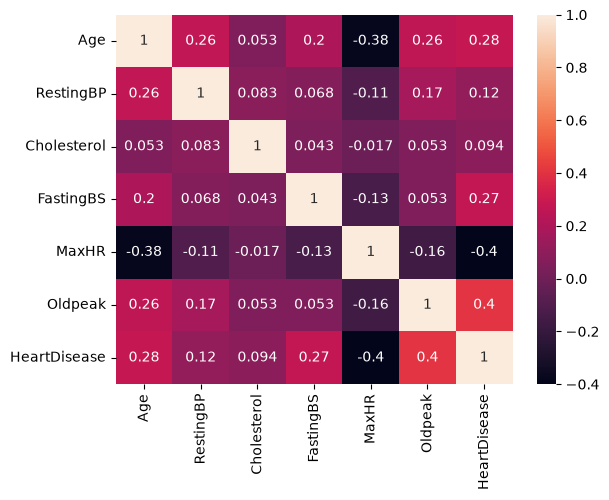

In [154]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

In [155]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    float64
 4   Cholesterol     918 non-null    float64
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 97.6 KB


In [156]:
df['Sex'].value_counts()

Sex
M    725
F    193
Name: count, dtype: int64

In [157]:
df['Sex']=df['Sex'].map({
    'M':1,
    'F':0
})


In [158]:
df['ChestPainType'].value_counts()

ChestPainType
ASY    496
NAP    203
ATA    173
TA      46
Name: count, dtype: int64

In [159]:
df=pd.get_dummies(df,columns=['ChestPainType','RestingECG','ST_Slope'],drop_first=False)

In [160]:
df['ExerciseAngina']=df['ExerciseAngina'].map({
    'N':0,
    'Y':1

})

In [161]:
df= df.astype(int)

In [162]:
df.head(10)

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,HeartDisease,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up
0,40,1,140,289,0,172,0,0,0,0,1,0,0,0,1,0,0,0,1
1,49,0,160,180,0,156,0,1,1,0,0,1,0,0,1,0,0,1,0
2,37,1,130,283,0,98,0,0,0,0,1,0,0,0,0,1,0,0,1
3,48,0,138,214,0,108,1,1,1,1,0,0,0,0,1,0,0,1,0
4,54,1,150,195,0,122,0,0,0,0,0,1,0,0,1,0,0,0,1
5,39,1,120,339,0,170,0,0,0,0,0,1,0,0,1,0,0,0,1
6,45,0,130,237,0,170,0,0,0,0,1,0,0,0,1,0,0,0,1
7,54,1,110,208,0,142,0,0,0,0,1,0,0,0,1,0,0,0,1
8,37,1,140,207,0,130,1,1,1,1,0,0,0,0,1,0,0,1,0
9,48,0,120,284,0,120,0,0,0,0,1,0,0,0,1,0,0,0,1


In [163]:
from sklearn.preprocessing import StandardScaler
col=['Age','RestingBP','Cholesterol','MaxHR','Oldpeak']

scaler= StandardScaler()
df[col]= scaler.fit_transform(df[col])


In [164]:
df.head()

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,HeartDisease,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up
0,-1.433140,1,0.414885,0.834754,0,1.382928,0,-0.727592,0,0,1,0,0,0,1,0,0,0,1
1,-0.478484,0,1.527224,-1.210675,0,0.754157,0,0.282891,1,0,0,1,0,0,1,0,0,1,0
2,-1.751359,1,-0.141284,0.722161,0,-1.525138,0,-0.727592,0,0,1,0,0,0,0,1,0,0,1
3,-0.584556,0,0.303651,-0.572651,0,-1.132156,1,0.282891,1,1,0,0,0,0,1,0,0,1,0
4,0.051881,1,0.971054,-0.929194,0,-0.581981,0,-0.727592,0,0,0,1,0,0,1,0,0,0,1
